# Entrega 02 — Análise de Regressão
### Base: `base_analitica_amostra.xlsx`

**Objetivo:** ajustar um modelo de regressão linear para explorar relações entre contas da simulação financeira, interpretar os coeficientes, avaliar a qualidade do ajuste, apresentar diagnósticos e registrar as limitações.

**Pergunta de pesquisa:** *quais direcionadores explicam a variação do **Resultado Líquido** (DRE) entre os cenários simulados?*

Roteiro: (1) preparação dos dados → (2) escolha de variáveis → (3) modelos M1, M2, M3 → (4) interpretação → (5) qualidade do ajuste → (6) robustez → (7) diagnósticos → (8) limitações.

## 1. Preparação dos dados

In [1]:
import json
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 120})
NAVY, RED, ORANGE = '#2E5266', '#C0392B', '#E67E22'
import os; os.makedirs('charts', exist_ok=True)

df = pd.read_excel('base_analitica_amostra.xlsx', sheet_name='in')
print(df.shape)

(1000, 9)


### 1.1 Da base "longa" para a base "larga"
Na base original cada linha é um par *(conta, cenário)*. Para regredir uma conta em outras, a **unidade de observação precisa ser o cenário**: cada cenário passa a ser uma linha e cada conta uma coluna. Regredir diretamente sobre as 1.000 linhas misturaria contas de naturezas distintas e não teria interpretação econômica.

In [2]:
w = df.pivot_table(index='cenario_num', columns='conta_normalizada', values='valor', aggfunc='first') / 1e6  # R$ milhões
print("Cenários x contas:", w.shape)

# Completude: a amostra de 1.000 linhas foi truncada no cenário 15
print("\nLinhas por cenário:"); print(df.groupby('cenario_num').size().to_string())
print("\nContas DRE sem valor no cenário 15:", int(w.loc[15, [c for c in w.columns if c.startswith('DRE')]].isna().sum()))

Cenários x contas: (15, 68)

Linhas por cenário:
cenario_num
1     68
2     68
3     68
4     68
5     68
6     68
7     68
8     68
9     68
10    68
11    68
12    68
13    68
14    68
15    48

Contas DRE sem valor no cenário 15: 8


**Atenção:** o cenário 15 possui apenas 48 das 68 contas (a amostra de 1.000 linhas foi cortada). Como o Resultado Líquido e a Receita (DRE) não existem nesse cenário, a regressão usa **n = 14 observações**. Isso é uma limitação central (seção 8).

## 2. Escolha da variável resposta e dos preditores

- **Resposta (y):** `DRE - Resultado Líquido`.
- **Candidatos:** Receita, Despesas Financeiras, Receitas Financeiras (todas DRE).
- **Excluídas por identidade contábil** (o modelo ficaria "perfeito" por construção, sem informação): Imposto de Renda (é função linear exata do resultado), Resultado Antes do IR, EBITDA, Resultado Operacional, Geração de Caixa e Saldo (derivam do próprio resultado), além de `Resultado Líquido após Equivalência` (idêntico à resposta).

In [3]:
d = pd.DataFrame({
    'RL':  w['DRE - Resultado Líquido'],
    'REC': w['DRE - Receita'],
    'DF':  w['DRE - Despesas Financeiras'],
    'RF':  w['DRE - Receitas Financeiras'],
}).dropna()
n = len(d); print("n =", n)

# Evidência das identidades contábeis
print("corr(RL, Imposto de Renda)       =", round(w['DRE - Resultado Líquido'].corr(w['DRE - Imposto de Renda e Contribuição Social']), 6))
print("corr(RL, Resultado Líq. após Eq.) =", round(w['DRE - Resultado Líquido'].corr(w['DRE - Resultado Líquido após Equivalência']), 6))
aliq = (-w['DRE - Imposto de Renda e Contribuição Social'] / w['DRE - Resultado Antes do Imposto de Renda']).dropna()
print("Alíquota efetiva IR/RAIR: média = %.4f, desvio = %.6f" % (aliq.mean(), aliq.std()))
d.describe().T.round(2)

n = 14
corr(RL, Imposto de Renda)       = -1.0
corr(RL, Resultado Líq. após Eq.) = 1.0
Alíquota efetiva IR/RAIR: média = 0.3438, desvio = 0.000000


,count,mean,std,min,25%,50%,75%,max
RL,14.0,2433.38,12.23,2416.01,2426.76,2430.26,2436.27,2459.25
REC,14.0,6683.49,24.89,6657.55,6665.91,6672.56,6702.64,6730.50
DF,14.0,-682.07,11.15,-704.29,-692.27,-679.98,-672.72,-668.46
RF,14.0,95.95,3.05,90.76,93.50,97.48,98.43,99.64


A alíquota efetiva é **constante (~34,4%)** entre cenários — informação útil para interpretar os coeficientes adiante.

        RL    REC     DF     RF
RL   1.000  0.818  0.411 -0.726
REC  0.818  1.000 -0.186 -0.813
DF   0.411 -0.186  1.000  0.007
RF  -0.726 -0.813  0.007  1.000


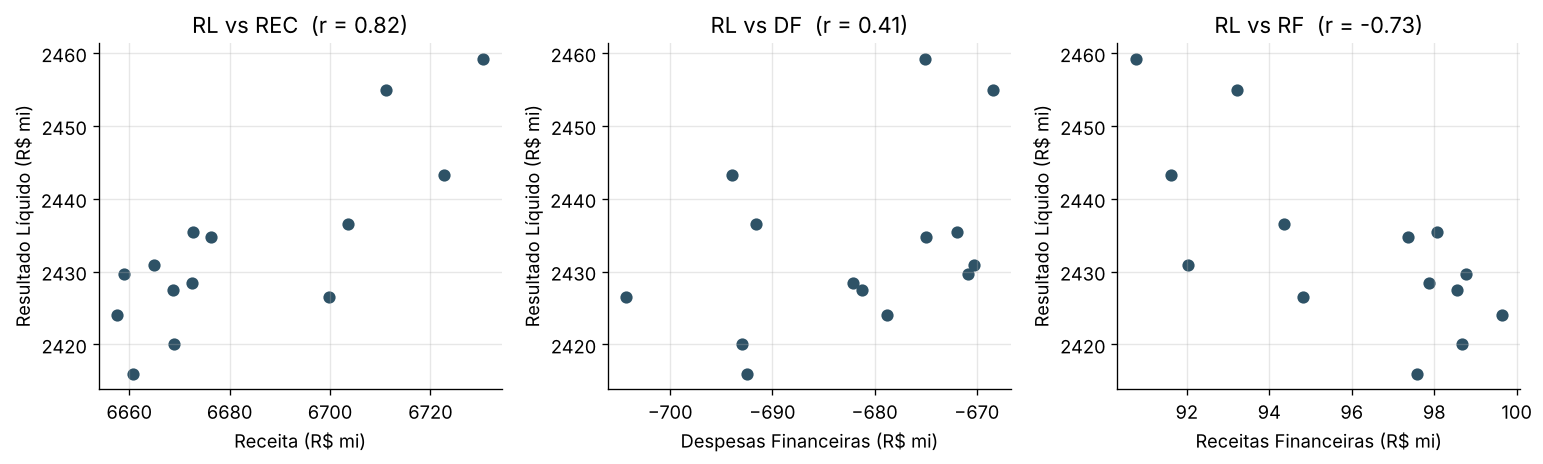

In [4]:
print(d.corr().round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
labels = {'REC': 'Receita (R$ mi)', 'DF': 'Despesas Financeiras (R$ mi)', 'RF': 'Receitas Financeiras (R$ mi)'}
for ax, v in zip(axes, ['REC', 'DF', 'RF']):
    ax.scatter(d[v], d['RL'], color=NAVY, s=40)
    ax.set_xlabel(labels[v]); ax.set_ylabel('Resultado Líquido (R$ mi)')
    ax.set_title(f'RL vs {v}  (r = {d[v].corr(d["RL"]):.2f})')
plt.tight_layout(); plt.savefig('charts/dispersao_preditores.png', dpi=150); plt.show()

Receita tem correlação forte com o resultado (0,82), mas Receitas Financeiras também se correlaciona fortemente com Receita (−0,81) — sinal de possível multicolinearidade, que será checado via VIF.

## 3. Modelos ajustados (MQO)

Modelos aninhados, do mais simples ao mais completo:

- **M1:** RL = β₀ + β₁·REC + ε
- **M2:** RL = β₀ + β₁·REC + β₂·DF + ε
- **M3:** RL = β₀ + β₁·REC + β₂·DF + β₃·RF + ε

In [5]:
specs = {'M1': ['REC'], 'M2': ['REC', 'DF'], 'M3': ['REC', 'DF', 'RF']}
fits = {k: sm.OLS(d['RL'], sm.add_constant(d[v])).fit() for k, v in specs.items()}
print(fits['M1'].summary())

                            OLS Regression Results                            
Dep. Variable:                     RL   R-squared:                       0.670
Model:                            OLS   Adj. R-squared:                  0.642
Method:                 Least Squares   F-statistic:                     24.32
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           0.000347
Time:                        23:02:42   Log-Likelihood:                -46.646
No. Observations:                  14   AIC:                             97.29
Df Residuals:                      12   BIC:                             98.57
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -253.2836    544.785     -0.465      0.6

In [6]:
print(fits['M2'].summary())

                            OLS Regression Results                            
Dep. Variable:                     RL   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                     3093.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           7.43e-16
Time:                        23:02:42   Log-Likelihood:                -10.061
No. Observations:                  14   AIC:                             26.12
Df Residuals:                      11   BIC:                             28.04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -173.2047     41.745     -4.149      0.0

In [7]:
print(fits['M3'].summary())

                            OLS Regression Results                            
Dep. Variable:                     RL   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 5.745e+04
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.78e-21
Time:                        23:02:42   Log-Likelihood:                 13.884
No. Observations:                  14   AIC:                            -19.77
Df Residuals:                      10   BIC:                            -17.21
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -396.0540     15.181    -26.088      0.0

## 4. Interpretação dos coeficientes (M3 — modelo final)

In [8]:
m = fits['M3']; cols = specs['M3']
ic = m.conf_int(); ic.columns = ['IC95_inf', 'IC95_sup']
beta_pad = m.params[1:] * d[cols].std() / d['RL'].std()
tab = pd.concat([m.params.rename('coef'), m.bse.rename('erro_pad'), m.tvalues.rename('t'),
                 m.pvalues.rename('p-valor'), ic], axis=1)
tab['beta_padronizado'] = beta_pad
tab.round(4)

,coef,erro_pad,t,p-valor,IC95_inf,IC95_sup,beta_padronizado
const,-396.0540,15.1814,-26.0880,0.0,-429.8803,-362.2276,NaN
REC,0.4856,0.0021,227.3839,0.0,0.4809,0.4904,0.9886
DF,0.6516,0.0028,234.6756,0.0,0.6454,0.6578,0.5944
RF,0.2944,0.0171,17.2026,0.0,0.2563,0.3325,0.0735


**Leitura (valores em R$ milhões):**

- **Receita (β ≈ 0,486):** mantidas as demais variáveis, +R$ 1 milhão de receita eleva o Resultado Líquido em ≈ R$ 0,49 milhão. É coerente com o repasse da receita ao lucro após custos variáveis, tributos sobre receita (~7%) e IR (~34%).
- **Despesas Financeiras (β ≈ 0,652):** a conta é registrada com **sinal negativo**; logo, uma despesa R$ 1 milhão *maior* (valor mais negativo) reduz o resultado em ≈ R$ 0,65 milhão. O número ≈ 1 − 0,344 (alíquota efetiva): o efeito é o impacto **líquido de IR** — o modelo "reencontra" a estrutura tributária.
- **Receitas Financeiras (β ≈ 0,294):** efeito positivo, porém **menor que o esperado (~0,66)** e com peso padronizado pequeno (≈ 0,07). Como se correlaciona com Receita (−0,81), seu coeficiente é o menos estável (ver bootstrap).
- **Intercepto (≈ −396):** valor extrapolado para receita e resultados financeiros iguais a zero — **fora do intervalo observado**, sem interpretação prática.
- **Importância relativa (β padronizado):** Receita (≈ 0,99) > Despesas Financeiras (≈ 0,59) > Receitas Financeiras (≈ 0,07).

## 5. Qualidade do ajuste

In [9]:
def loocv_rmse(X, y):
    erros = []
    for i in range(len(y)):
        tr = np.arange(len(y)) != i
        mm = sm.OLS(y[tr], sm.add_constant(X[tr], has_constant='add')).fit()
        erros.append(y[i] - mm.predict(np.r_[1, X[i]].reshape(1, -1))[0])
    return float(np.sqrt(np.mean(np.square(erros))))

metricas = {}
for k, mm in fits.items():
    metricas[k] = dict(R2=mm.rsquared, R2_ajust=mm.rsquared_adj, AIC=mm.aic, BIC=mm.bic,
                       RMSE=float(np.sqrt(np.mean(mm.resid**2))), MAE=float(np.mean(np.abs(mm.resid))),
                       sigma_res=float(np.sqrt(mm.mse_resid)), F=mm.fvalue, p_F=mm.f_pvalue,
                       RMSE_LOOCV=loocv_rmse(d[specs[k]].values, d['RL'].values))
met = pd.DataFrame(metricas).T
met.round(4)

,R2,R2_ajust,AIC,BIC,RMSE,MAE,sigma_res,F,p_F,RMSE_LOOCV
M1,0.6696,0.6421,97.2922,98.5703,6.7729,5.7677,7.3155,24.3209,0.0003,8.0373
M2,0.9982,0.9979,26.1224,28.0395,0.4964,0.3322,0.5601,3092.9450,0.0000,0.6120
M3,0.9999,0.9999,-19.7684,-17.2122,0.0898,0.0721,0.1062,57445.4904,0.0000,0.1161


M1 -> M2: F = 2036.4, p = 7.73e-14
M2 -> M3: F = 295.9, p = 9.31e-09


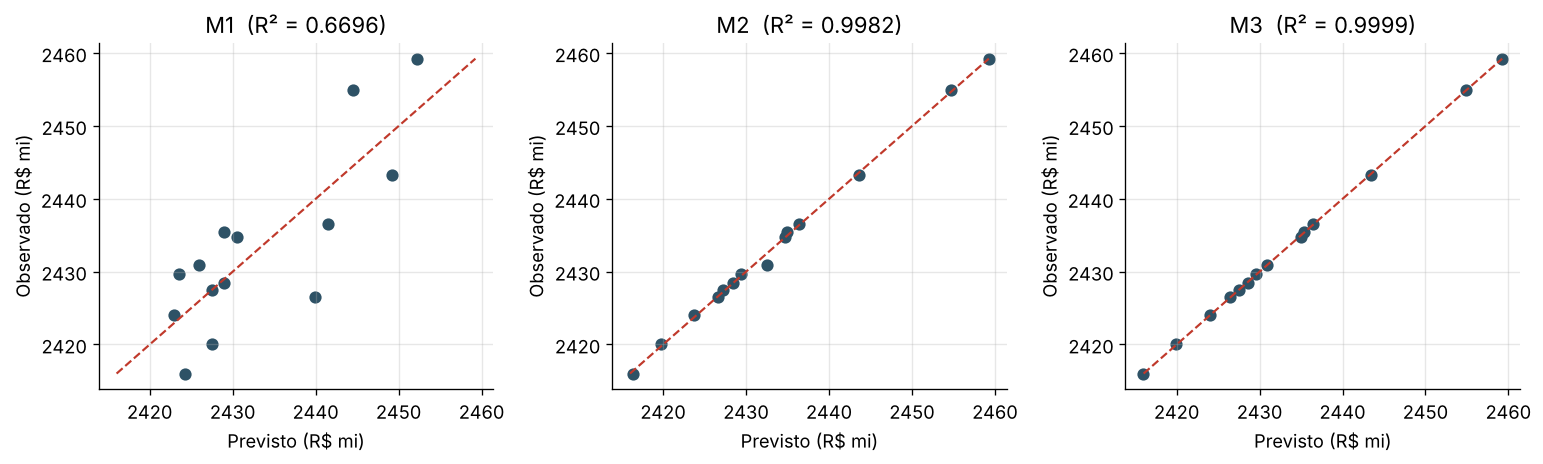

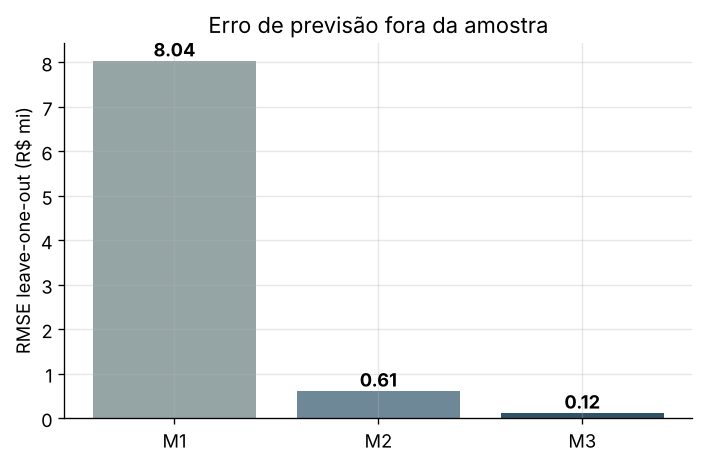

In [10]:
f12 = fits['M2'].compare_f_test(fits['M1']); f23 = fits['M3'].compare_f_test(fits['M2'])
print("M1 -> M2: F = %.1f, p = %.2e" % (f12[0], f12[1]))
print("M2 -> M3: F = %.1f, p = %.2e" % (f23[0], f23[1]))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, k in zip(axes, ['M1', 'M2', 'M3']):
    ax.scatter(fits[k].fittedvalues, d['RL'], color=NAVY, s=40)
    lo, hi = d['RL'].min(), d['RL'].max()
    ax.plot([lo, hi], [lo, hi], color=RED, ls='--', lw=1.3)
    ax.set_title(f"{k}  (R² = {fits[k].rsquared:.4f})")
    ax.set_xlabel('Previsto (R$ mi)'); ax.set_ylabel('Observado (R$ mi)')
plt.tight_layout(); plt.savefig('charts/obs_vs_previsto.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['M1', 'M2', 'M3'], met['RMSE_LOOCV'], color=[ '#95A5A6', '#6E8898', NAVY])
for i, v in enumerate(met['RMSE_LOOCV']): ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('RMSE leave-one-out (R$ mi)'); ax.set_title('Erro de previsão fora da amostra')
plt.tight_layout(); plt.savefig('charts/comparacao_modelos.png', dpi=150); plt.show()

**Leitura:** a Receita sozinha (M1) explica ≈ 67% da variância do resultado; incluir Despesas Financeiras (M2) leva o R² a ≈ 99,8% e Receitas Financeiras (M3) a ≈ 99,99%. Os testes F aninhados rejeitam a hipótese de que os termos adicionais são nulos, e AIC, BIC e o erro leave-one-out caem a cada etapa — **M3 é o melhor modelo** nos três critérios. O RMSE leave-one-out de M3 (≈ R$ 0,12 mi) é pequeno diante do desvio padrão do resultado (≈ R$ 12 mi).

> **Cuidado ao interpretar o R² ≈ 1:** o Resultado Líquido é *construído* a partir dessas contas por regras contábeis. O ajuste quase perfeito reflete **estrutura determinística do modelo financeiro**, não uma relação empírica "descoberta".

## 6. Robustez dos coeficientes (n pequeno)

In [11]:
X3 = sm.add_constant(d[specs['M3']])
robusto = fits['M3'].get_robustcov_results('HC3')
rob = pd.DataFrame({'coef': robusto.params, 'erro_HC3': robusto.bse, 'p_HC3': robusto.pvalues}, index=X3.columns)
print("Erros-padrão robustos (HC3):"); print(rob.round(5))

rng = np.random.default_rng(42); boot = []
for _ in range(5000):
    dd = d.iloc[rng.integers(0, n, n)]
    try: boot.append(sm.OLS(dd['RL'], sm.add_constant(dd[specs['M3']])).fit().params.values)
    except Exception: pass
boot = np.array(boot)
ic_boot = pd.DataFrame(np.percentile(boot, [2.5, 97.5], axis=0).T, index=X3.columns, columns=['boot_inf', 'boot_sup'])
comp = pd.concat([fits['M3'].conf_int().rename(columns={0: 'ols_inf', 1: 'ols_sup'}), ic_boot], axis=1)
print("\nIC 95%: analítico (OLS) vs bootstrap (5.000 reamostragens)"); print(comp.round(4))

Erros-padrão robustos (HC3):
            coef  erro_HC3  p_HC3
const -396.05396  11.22654    0.0
REC      0.48562   0.00157    0.0
DF       0.65163   0.00274    0.0
RF       0.29439   0.01301    0.0



IC 95%: analítico (OLS) vs bootstrap (5.000 reamostragens)
        ols_inf   ols_sup  boot_inf  boot_sup
const -429.8803 -362.2276 -881.6421 -355.0790
REC      0.4809    0.4904    0.4798    0.5510
DF       0.6454    0.6578    0.6451    0.6575
RF       0.2563    0.3325    0.2449    0.8238


Os erros-padrão HC3 são da mesma ordem dos clássicos, e o bootstrap confirma o sinal e a ordem de grandeza de Receita e Despesas Financeiras. **O intervalo bootstrap de Receitas Financeiras é bem mais largo que o analítico** — confirmação de que essa estimativa é frágil com apenas 14 observações.

## 7. Diagnósticos do modelo (M3)

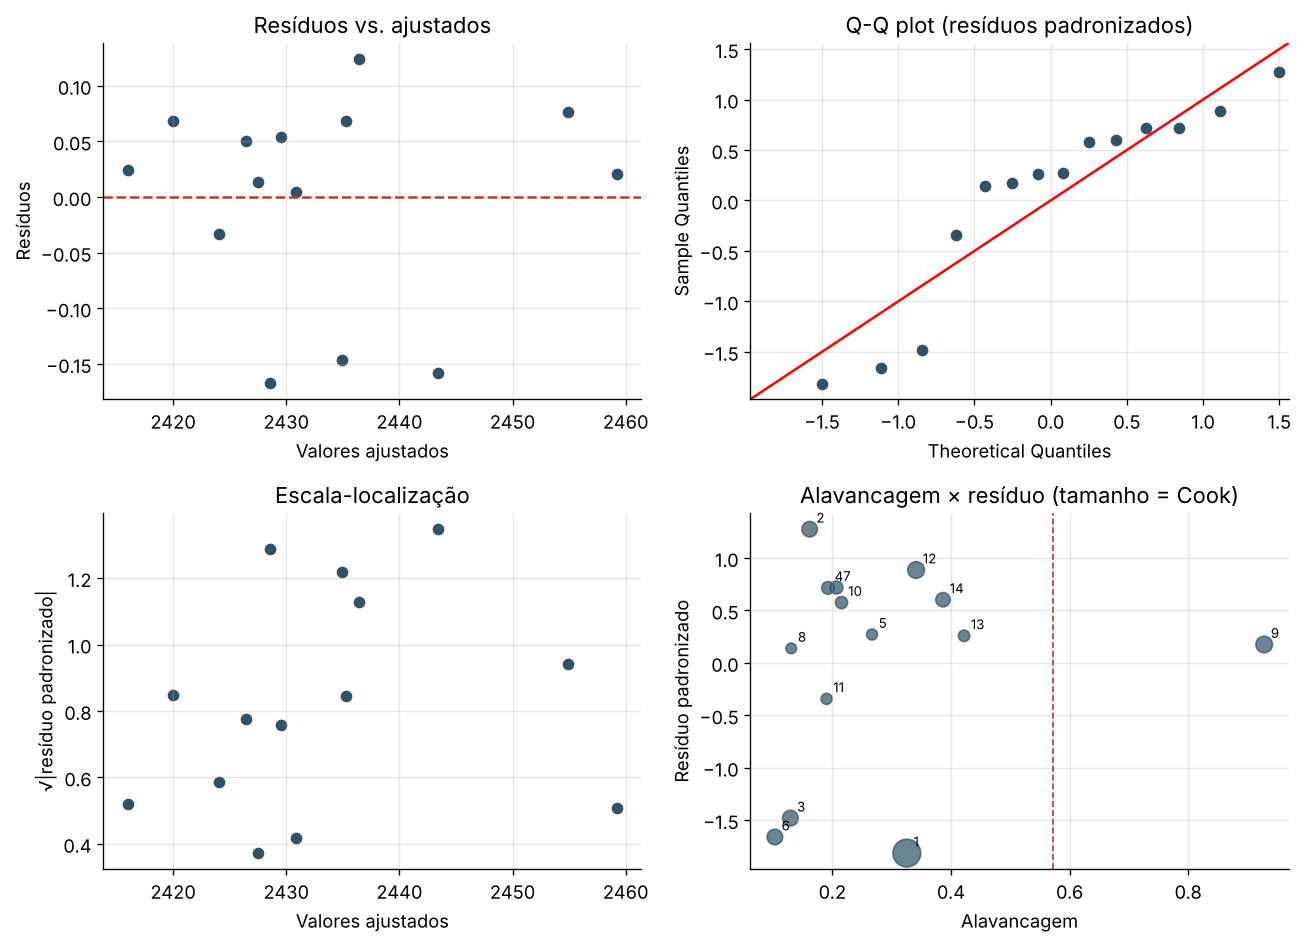

In [12]:
m = fits['M3']; infl = OLSInfluence(m)
res_pad = np.asarray(infl.resid_studentized_internal); lev = np.asarray(infl.hat_matrix_diag)
cook = np.asarray(infl.cooks_distance[0]); fitted = m.fittedvalues
p = len(m.params)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0,0].scatter(fitted, m.resid, color=NAVY); ax[0,0].axhline(0, color=RED, ls='--')
ax[0,0].set_xlabel('Valores ajustados'); ax[0,0].set_ylabel('Resíduos'); ax[0,0].set_title('Resíduos vs. ajustados')
sm.qqplot(res_pad, line='45', ax=ax[0,1], markerfacecolor=NAVY, markeredgecolor=NAVY)
ax[0,1].set_title('Q-Q plot (resíduos padronizados)')
ax[1,0].scatter(fitted, np.sqrt(np.abs(res_pad)), color=NAVY)
ax[1,0].set_xlabel('Valores ajustados'); ax[1,0].set_ylabel('√|resíduo padronizado|'); ax[1,0].set_title('Escala-localização')
ax[1,1].scatter(lev, res_pad, s=40 + 600*cook, color=NAVY, alpha=.7)
for i, idx in enumerate(d.index): ax[1,1].annotate(str(idx), (lev[i], res_pad[i]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax[1,1].axvline(2*p/n, color=RED, ls='--', lw=1); ax[1,1].set_xlabel('Alavancagem'); ax[1,1].set_ylabel('Resíduo padronizado')
ax[1,1].set_title('Alavancagem × resíduo (tamanho = Cook)')
plt.tight_layout(); plt.savefig('charts/diagnosticos.png', dpi=150); plt.show()

In [13]:
Xs = sm.add_constant(d[specs['M3']])
vif = pd.Series([variance_inflation_factor(Xs.values, i) for i in range(1, Xs.shape[1])], index=specs['M3'])
sw = stats.shapiro(m.resid); bp = het_breuschpagan(m.resid, Xs); dw = durbin_watson(m.resid)
print("VIF:\n", vif.round(2).to_string())
print("\nShapiro-Wilk (normalidade): W = %.3f, p = %.3f" % sw)
print("Breusch-Pagan (homocedasticidade): LM = %.3f, p = %.3f" % (bp[0], bp[1]))
print("Durbin-Watson: %.3f  (a ordem dos cenários é arbitrária — uso apenas informativo)" % dw)

inf = pd.DataFrame({'alavancagem': lev, 'Cook': cook, 'resid_stud_externo': np.asarray(infl.resid_studentized_external)}, index=d.index)
print("\nLimiares: alavancagem > %.2f ; Cook > %.2f" % (2*p/n, 4/n))
inf.round(3)

VIF:
 REC    3.26
DF     1.11
RF     3.15

Shapiro-Wilk (normalidade): W = 0.855, p = 0.026
Breusch-Pagan (homocedasticidade): LM = 1.575, p = 0.665
Durbin-Watson: 2.855  (a ordem dos cenários é arbitrária — uso apenas informativo)

Limiares: alavancagem > 0.57 ; Cook > 0.29


,alavancagem,Cook,resid_stud_externo
cenario_num,,,
1,0.326,0.397,-2.103
2,0.162,0.078,1.322
3,0.129,0.081,-1.591
4,0.193,0.031,0.697
5,0.267,0.007,0.258
6,0.103,0.079,-1.852
7,0.207,0.034,0.700
8,0.131,0.001,0.131
9,0.928,0.099,0.166


| Diagnóstico | Resultado | Leitura |
|---|---|---|
| Multicolinearidade | VIF ≤ 3,3 | Moderada; abaixo de 5. Número de condição padronizado ≈ 3,3 |
| Normalidade dos resíduos | Shapiro p ≈ 0,026 | Rejeitada a 5%: o Q-Q plot mostra cauda inferior mais pesada (três resíduos negativos maiores que o esperado); desvio de pequena magnitude, mas n = 14 |
| Homocedasticidade | Breusch-Pagan p ≈ 0,67 | Sem evidência de heterocedasticidade |
| Autocorrelação | DW ≈ 2,86 | Sem sentido causal: cenários não têm ordem temporal |
| Influência | Cenário 9: alavancagem ≈ 0,93; Cenário 1: Cook ≈ 0,40 | Dois pontos merecem atenção |

O cenário 9 tem alavancagem muito alta (valor extremo em algum preditor) mas resíduo pequeno: ele **ancora** o plano de regressão sem distorcê-lo. O cenário 1 tem a maior distância de Cook, ainda moderada. Vale testar a sensibilidade removendo-os:

In [14]:
sens = {}
for rotulo, excl in [('Completo', []), ('Sem cenário 9', [9]), ('Sem cenário 1', [1]), ('Sem 1 e 9', [1, 9])]:
    dd = d.drop(index=excl)
    mm = sm.OLS(dd['RL'], sm.add_constant(dd[specs['M3']])).fit()
    sens[rotulo] = {**mm.params.to_dict(), 'R2': mm.rsquared, 'n': len(dd)}
sens = pd.DataFrame(sens).T; sens.round(4)

,const,REC,DF,RF,R2,n
Completo,-396.0540,0.4856,0.6516,0.2944,0.9999,14.0
Sem cenário 9,-404.4911,0.4867,0.6516,0.3040,0.9999,13.0
Sem cenário 1,-400.3114,0.4862,0.6501,0.2897,1.0000,13.0
Sem 1 e 9,-396.2930,0.4856,0.6502,0.2851,1.0000,12.0


Os coeficientes de Receita e Despesas Financeiras praticamente não se alteram. O de Receitas Financeiras varia entre ≈ 0,285 e 0,304 (cerca de ±3%): pouco em termos absolutos, mas é a maior oscilação relativa entre os coeficientes. A incerteza revelada pelo bootstrap (seção 6) é bem maior que a revelada por essa exclusão de pontos.

## 8. Limitações da análise

1. **Amostra pequena (n = 14).** Só há 14 cenários completos para as contas DRE; com 3 preditores restam 10 graus de liberdade. Intervalos e testes têm baixo poder para detectar problemas, e o coeficiente de Receitas Financeiras é estimado com pouca precisão (intervalo bootstrap bem mais largo que o analítico).
2. **Amostra truncada.** O cenário 15 está incompleto (20 contas sem valor) — provavelmente corte da amostra em 1.000 linhas. Não há como saber se a omissão é aleatória.
3. **Relações contábeis, não causais.** O resultado é função aritmética de suas componentes. R² ≈ 1 e coeficientes que reproduzem a alíquota (1 − 0,344) mostram que o modelo recupera a *estrutura do simulador*, não um comportamento econômico independente.
4. **Variação minúscula frente ao nível.** Em torno de 0,4% de coeficiente de variação na Receita: os resultados valem **somente para o intervalo simulado** e não devem ser extrapolados (o intercepto, por exemplo, está fora dele).
5. **Multicolinearidade moderada** entre Receita e Receitas Financeiras (r = −0,81), que prejudica a separação dos efeitos.
6. **Pressupostos testados com poder limitado.** Normalidade rejeitada a 5% (Shapiro p ≈ 0,026), com cauda inferior mais pesada no Q-Q plot; homocedasticidade e independência não verificáveis de forma conclusiva; Durbin-Watson não se aplica (sem ordem temporal).
7. **Possível dependência entre cenários.** Se os cenários vierem de uma mesma simulação (Monte Carlo), as observações podem não ser independentes.
8. **Pesos de cenário ignorados.** `peso_cenario` é praticamente constante (≈ 0,0251), logo MQP seria equivalente a MQO.
9. **Um único período** ("Ano 1"): não há como avaliar estabilidade temporal.

**Próximos passos sugeridos:** obter a base completa (todos os cenários e anos) e ampliar n; usar variáveis exógenas do simulador (premissas macro) em vez de contas derivadas; avaliar modelos regularizados (Ridge/Lasso) se o número de preditores crescer.

## 9. Exportação dos resultados (usados no relatório)

In [15]:
saida = {
    'n': int(n),
    'metricas': met.to_dict(orient='index'),
    'coef': tab.reset_index().rename(columns={'index': 'termo'}).to_dict(orient='records'),
    'hc3': rob.reset_index().rename(columns={'index': 'termo'}).to_dict(orient='records'),
    'ic_boot': comp.reset_index().rename(columns={'index': 'termo'}).to_dict(orient='records'),
    'vif': vif.to_dict(),
    'shapiro': {'W': float(sw[0]), 'p': float(sw[1])},
    'bp': {'LM': float(bp[0]), 'p': float(bp[1])},
    'dw': float(dw),
    'f12': {'F': float(f12[0]), 'p': float(f12[1])}, 'f23': {'F': float(f23[0]), 'p': float(f23[1])},
    'influencia': inf.reset_index().to_dict(orient='records'),
    'sensibilidade': sens.reset_index().rename(columns={'index': 'cenario'}).to_dict(orient='records'),
    'aliquota': {'media': float(aliq.mean()), 'dp': float(aliq.std())},
    'desc': d.describe().T.reset_index().to_dict(orient='records'),
    'corr': d.corr().to_dict(),
}
with open('results.json', 'w') as f: json.dump(json.loads(json.dumps(saida, default=float).replace('NaN', 'null')), f, indent=1)
print('results.json salvo')

results.json salvo
